## Improvement to the model

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42

In [2]:
PROJECT_ROOT = Path.cwd().parent
DATASET = "FD002"  # Change to FD001, FD002, FD003, or FD004

DATA_PATH = PROJECT_ROOT / "data" / "raw" / f"train_{DATASET}.txt"

RESULTS_PATH = PROJECT_ROOT / "results"
FIGURES_PATH = RESULTS_PATH / "figures" / DATASET
METRICS_PATH = RESULTS_PATH / "metrics"

FIGURES_PATH.mkdir(parents=True, exist_ok=True)
METRICS_PATH.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Training file exists:", DATA_PATH.exists())
# Keep this value aligned with the cap used in the final evaluation notebook.


Project folder: /Users/aisha/mma3001-project
Training file exists: True


In [3]:
index_columns = [
    "engine_id",
    "cycle",
]

setting_columns = [
    "setting_1",
    "setting_2",
    "setting_3",
]

sensor_columns = [
    f"sensor_{number}" for number in range(1, 22)
]

column_names = (
    index_columns
    + setting_columns
    + sensor_columns
)

print("Number of columns:", len(column_names))

Number of columns: 26


In [4]:
train = pd.read_csv(
    DATA_PATH,
    sep=r"\s+",
    header=None,
    names=column_names
)

print("Dataset shape:", train.shape)
print("Number of engines:", train["engine_id"].nunique())

train.head()

Dataset shape: (53759, 26)
Number of engines: 260


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,...,183.06,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,...,130.42,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,...,164.22,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723
3,1,4,42.0077,0.8416,100.0,445.00,549.51,1354.03,1126.38,3.91,...,130.72,2387.61,8068.66,9.3528,0.02,329,2212,100.00,10.59,6.4701
4,1,5,25.0005,0.6203,60.0,462.54,537.07,1257.71,1047.93,7.05,...,164.31,2028.00,7861.23,10.8963,0.02,309,1915,84.93,14.13,8.5286


In [5]:
maximum_cycles = (
    train.groupby("engine_id")["cycle"]
    .max()
    .rename("maximum_cycle")
)

train = train.merge(
    maximum_cycles,
    on="engine_id",
    how="left",
    validate="many_to_one"
)

train["RUL_raw"] = (
    train["maximum_cycle"]
    - train["cycle"]
)

train[
    [
        "engine_id",
        "cycle",
        "maximum_cycle",
        "RUL_raw"
    ]
].head()

,engine_id,cycle,maximum_cycle,RUL_raw
0,1,1,149,148
1,1,2,149,147
2,1,3,149,146
3,1,4,149,145
4,1,5,149,144


In [6]:
RUL_CAP = 125

train["RUL_capped"] = train[
    "RUL_raw"
].clip(
    upper=RUL_CAP
)

print(
    train[
        ["RUL_raw", "RUL_capped"]
    ].describe()
)

            RUL_raw    RUL_capped
count  53759.000000  53759.000000
mean     108.154746     86.913354
std       69.180569     41.665602
min        0.000000      0.000000
25%       51.000000     51.000000
50%      103.000000    103.000000
75%      156.000000    125.000000
max      377.000000    125.000000


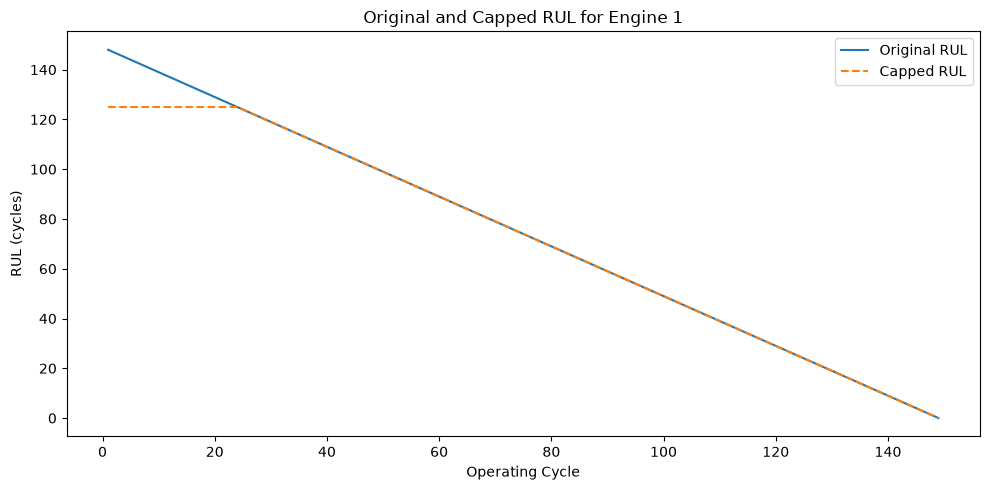

In [7]:
plt.figure(figsize=(10, 5))

engine_1 = train[
    train["engine_id"] == 1
]

plt.plot(
    engine_1["cycle"],
    engine_1["RUL_raw"],
    label="Original RUL"
)

plt.plot(
    engine_1["cycle"],
    engine_1["RUL_capped"],
    label="Capped RUL",
    linestyle="--"
)

plt.xlabel("Operating Cycle")
plt.ylabel("RUL (cycles)")
plt.title(
    "Original and Capped RUL for Engine 1"
)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "rul_capping_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
sensor_statistics = train[
    sensor_columns
].agg(
    ["mean", "std", "min", "max"]
).T

constant_sensors = sensor_statistics[
    sensor_statistics["std"] < 1e-8
].index.tolist()

usable_sensors = [
    sensor
    for sensor in sensor_columns
    if sensor not in constant_sensors
]

print("Constant sensors:")
print(constant_sensors)

print("\nUsable sensors:")
print(usable_sensors)

print(
    "\nNumber of usable sensors:",
    len(usable_sensors)
)

Constant sensors:
[]

Usable sensors:
['sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']

Number of usable sensors: 21


In [9]:
ROLLING_WINDOW = 5

for sensor in usable_sensors:
    train[
        f"{sensor}_rolling_mean"
    ] = (
        train
        .groupby("engine_id")[sensor]
        .transform(
            lambda x: x.rolling(
                window=ROLLING_WINDOW,
                min_periods=1
            ).mean()
        )
    )

In [10]:
for sensor in usable_sensors:
    train[
        f"{sensor}_rolling_std"
    ] = (
        train
        .groupby("engine_id")[sensor]
        .transform(
            lambda x: x.rolling(
                window=ROLLING_WINDOW,
                min_periods=2
            ).std()
        )
    )

In [11]:
for sensor in usable_sensors:
    train[
        f"{sensor}_delta"
    ] = (
        train
        .groupby("engine_id")[sensor]
        .diff()
        .fillna(0)
    )

In [12]:
baseline_features = (
    ["cycle"]
    + setting_columns
    + usable_sensors
)

rolling_mean_features = [
    f"{sensor}_rolling_mean"
    for sensor in usable_sensors
]

rolling_std_features = [
    f"{sensor}_rolling_std"
    for sensor in usable_sensors
]

delta_features = [
    f"{sensor}_delta"
    for sensor in usable_sensors
]

enhanced_features = (
    baseline_features
    + rolling_mean_features
    + rolling_std_features
    + delta_features
)

print(
    "Baseline features:",
    len(baseline_features)
)

print(
    "Enhanced features:",
    len(enhanced_features)
)

Baseline features: 25
Enhanced features: 88


In [13]:
groups = train[
    "engine_id"
].copy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

all_indices = np.arange(
    len(train)
)

train_indices, validation_indices = next(
    splitter.split(
        all_indices,
        groups=groups
    )
)

training_engines = set(
    groups.iloc[train_indices]
)

validation_engines = set(
    groups.iloc[validation_indices]
)

print(
    "Training engines:",
    len(training_engines)
)

print(
    "Validation engines:",
    len(validation_engines)
)

print(
    "Shared engines:",
    training_engines
    & validation_engines
)

assert training_engines.isdisjoint(
    validation_engines
)

Training engines: 208
Validation engines: 52
Shared engines: set()


In [14]:
def evaluate_model(
    name,
    y_true,
    y_prediction
):
    """Calculate regression performance metrics."""

    mae = mean_absolute_error(
        y_true,
        y_prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_prediction
        )
    )

    r_squared = r2_score(
        y_true,
        y_prediction
    )

    return {
        "model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r_squared,
    }

In [15]:
X_baseline = train[
    baseline_features
].copy()

y_original = train[
    "RUL_raw"
].copy()

X_train_baseline = X_baseline.iloc[
    train_indices
]

X_validation_baseline = X_baseline.iloc[
    validation_indices
]

y_train_original = y_original.iloc[
    train_indices
]

y_validation_original = y_original.iloc[
    validation_indices
]

In [16]:
baseline_rf = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        ),
    ]
)

baseline_rf.fit(
    X_train_baseline,
    y_train_original
)

baseline_predictions = baseline_rf.predict(
    X_validation_baseline
)

results = [
    evaluate_model(
        "Original RF",
        y_validation_original,
        baseline_predictions
    )
]

pd.DataFrame(results).round(3)

,model,MAE,RMSE,R2
0,Original RF,26.199,35.134,0.715


In [17]:
y_capped = train[
    "RUL_capped"
].copy()

y_train_capped = y_capped.iloc[
    train_indices
]

y_validation_capped = y_capped.iloc[
    validation_indices
]

capped_rf = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        ),
    ]
)

capped_rf.fit(
    X_train_baseline,
    y_train_capped
)

capped_predictions = capped_rf.predict(
    X_validation_baseline
)

results.append(
    evaluate_model(
        "RF + capped RUL",
        y_validation_capped,
        capped_predictions
    )
)

pd.DataFrame(results).round(3)

,model,MAE,RMSE,R2
0,Original RF,26.199,35.134,0.715
1,RF + capped RUL,11.650,16.738,0.840


In [18]:
X_enhanced = train[
    enhanced_features
].copy()

X_train_enhanced = X_enhanced.iloc[
    train_indices
]

X_validation_enhanced = X_enhanced.iloc[
    validation_indices
]

In [19]:
enhanced_rf = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        ),
    ]
)

enhanced_rf.fit(
    X_train_enhanced,
    y_train_capped
)

enhanced_predictions = enhanced_rf.predict(
    X_validation_enhanced
)

results.append(
    evaluate_model(
        "RF + capped RUL + trends",
        y_validation_capped,
        enhanced_predictions
    )
)

results_table = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

results_table.round(3)

,model,MAE,RMSE,R2
0,RF + capped RUL,11.650,16.738,0.840
1,RF + capped RUL + trends,11.849,16.901,0.836
2,Original RF,26.199,35.134,0.715


In [20]:
rf_model = enhanced_rf.named_steps[
    "regressor"
]

feature_importance = pd.DataFrame(
    {
        "feature": enhanced_features,
        "importance":
            rf_model.feature_importances_
    }
).sort_values(
    "importance",
    ascending=False
)

feature_importance.head(20)

,feature,importance
0,cycle,0.597655
14,sensor_11,0.080476
18,sensor_15,0.065314
7,sensor_4,0.060181
16,sensor_13,0.053944
17,sensor_14,0.020783
15,sensor_12,0.010515
5,sensor_2,0.009191
12,sensor_9,0.009074
6,sensor_3,0.007299


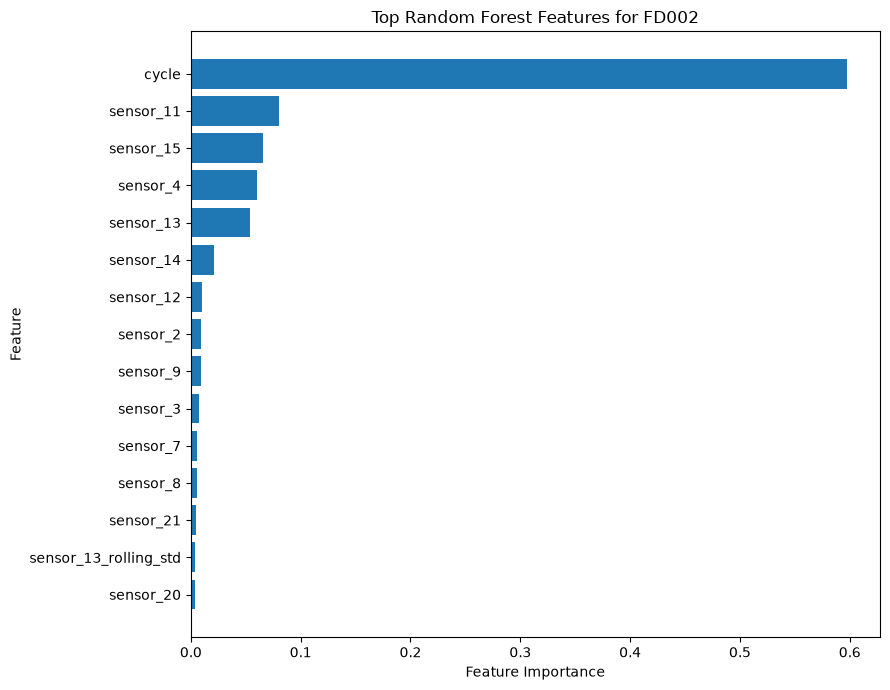

In [21]:
top_features = feature_importance.head(
    15
).sort_values(
    "importance"
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title(
    f"Top Random Forest Features for {DATASET}"
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "improved_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
parameter_options = [
    {
        "n_estimators": 100,
        "max_depth": 10,
        "min_samples_leaf": 2,
        "max_features": 1.0,
    },
    {
        "n_estimators": 200,
        "max_depth": 15,
        "min_samples_leaf": 2,
        "max_features": 1.0,
    },
    {
        "n_estimators": 300,
        "max_depth": 15,
        "min_samples_leaf": 4,
        "max_features": 1.0,
    },
    {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 4,
        "max_features": "sqrt",
    },
    {
        "n_estimators": 300,
        "max_depth": 20,
        "min_samples_leaf": 2,
        "max_features": 0.5,
    },
]

In [23]:
tuning_results = []

for params in parameter_options:

    model = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "regressor",
                RandomForestRegressor(
                    **params,
                    n_jobs=-1,
                    random_state=RANDOM_STATE
                )
            ),
        ]
    )

    model.fit(
        X_train_enhanced,
        y_train_capped
    )

    predictions = model.predict(
        X_validation_enhanced
    )

    metrics = evaluate_model(
        "Random Forest",
        y_validation_capped,
        predictions
    )

    tuning_results.append(
        {
            **params,
            **metrics,
        }
    )

tuning_table = (
    pd.DataFrame(tuning_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

tuning_table.round(3)

,n_estimators,max_depth,min_samples_leaf,max_features,model,MAE,RMSE,R2
0,300,20.0,2,0.5,Random Forest,11.723,16.602,0.842
1,300,15.0,4,1.0,Random Forest,11.843,16.879,0.837
2,200,15.0,2,1.0,Random Forest,11.861,16.906,0.836
3,300,NaN,4,sqrt,Random Forest,12.737,16.939,0.836
4,100,10.0,2,1.0,Random Forest,12.408,17.491,0.825


In [24]:
best_row = tuning_table.iloc[0]

best_parameters = {
    "n_estimators":
        int(best_row["n_estimators"]),

    "max_depth":
        (
            None
            if pd.isna(best_row["max_depth"])
            else int(best_row["max_depth"])
        ),

    "min_samples_leaf":
        int(best_row["min_samples_leaf"]),

    "max_features":
        best_row["max_features"],
}

print("Best parameters:")
print(best_parameters)

Best parameters:
{'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.5}


In [25]:
best_rf = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "regressor",
            RandomForestRegressor(
                **best_parameters,
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        ),
    ]
)

best_rf.fit(
    X_train_enhanced,
    y_train_capped
)

best_predictions = best_rf.predict(
    X_validation_enhanced
)

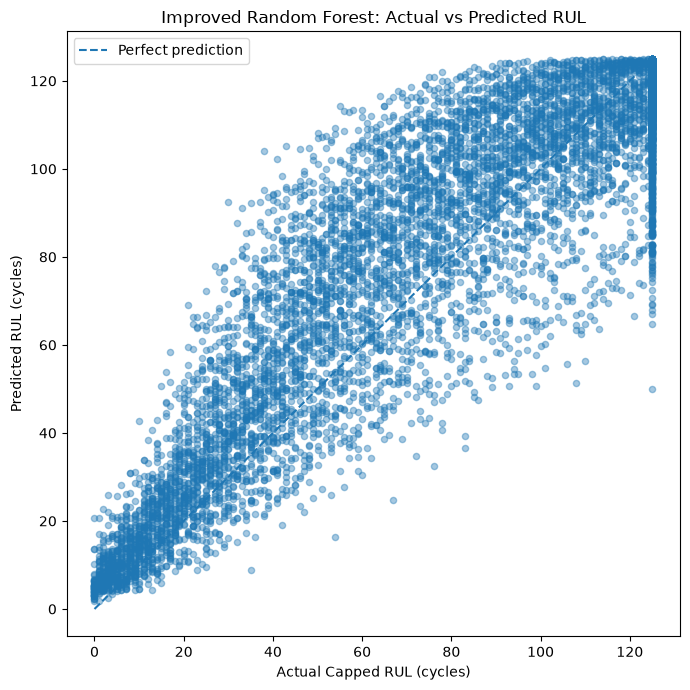

In [26]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_validation_capped,
    best_predictions,
    alpha=0.4,
    s=20
)

minimum_value = min(
    y_validation_capped.min(),
    best_predictions.min()
)

maximum_value = max(
    y_validation_capped.max(),
    best_predictions.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Capped RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")

plt.title(
    "Improved Random Forest: "
    "Actual vs Predicted RUL"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_PATH /
    "improved_validation_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

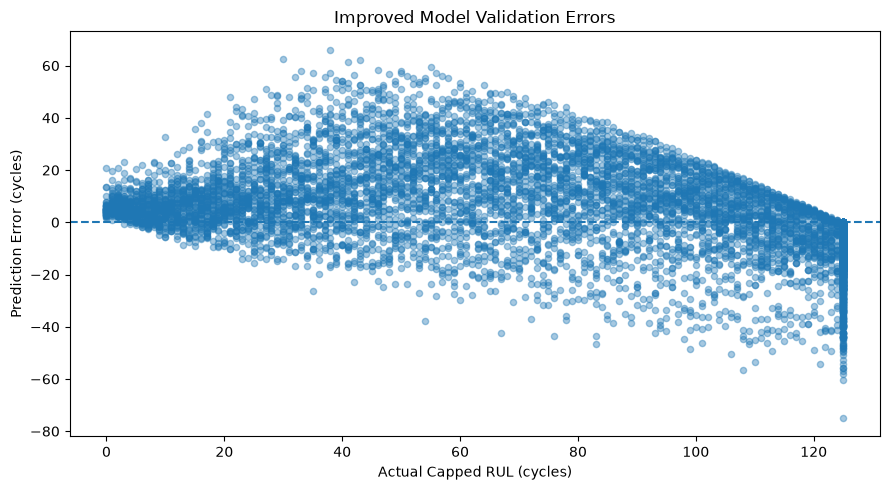

In [27]:
validation_errors = (
    best_predictions
    - y_validation_capped.to_numpy()
)

plt.figure(figsize=(9, 5))

plt.scatter(
    y_validation_capped,
    validation_errors,
    alpha=0.4,
    s=20
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Actual Capped RUL (cycles)")
plt.ylabel("Prediction Error (cycles)")
plt.title(
    "Improved Model Validation Errors"
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH /
    "improved_validation_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# testing section


In [28]:
RUL_CAPS = [100, 125, 150, 175]
cap_results = []

for cap in [100, 125, 150, 175]:

    y_capped_test = train["RUL_raw"].clip(upper=cap)

    y_train_cap = y_capped_test.iloc[train_indices]
    y_validation_cap = y_capped_test.iloc[validation_indices]

    model = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),
            (
                "regressor",
                RandomForestRegressor(
                    n_estimators=300,
                    max_depth=None,
                    min_samples_leaf=4,
                    max_features="sqrt",
                    n_jobs=-1,
                    random_state=RANDOM_STATE
                )
            ),
        ]
    )

    model.fit(
        X_train_enhanced,
        y_train_cap
    )

    predictions = model.predict(
        X_validation_enhanced
    )

    mae = mean_absolute_error(
        y_validation_cap,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_validation_cap,
            predictions
        )
    )

    r2 = r2_score(
        y_validation_cap,
        predictions
    )

    cap_results.append({
        "RUL_cap": cap,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

cap_results_table = pd.DataFrame(
    cap_results
).sort_values("RMSE")

cap_results_table.round(3)

,RUL_cap,MAE,RMSE,R2
0,100,8.727,12.554,0.851
1,125,12.737,16.939,0.836
2,150,16.897,21.348,0.816
3,175,20.477,25.371,0.793


In [29]:
cap_comparison = []

# Final observation for each validation engine
validation_data = train.iloc[validation_indices].copy()

validation_final_indices = (
    validation_data
    .sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .index
)

X_validation_final = train.loc[
    validation_final_indices,
    enhanced_features
]

y_validation_final_raw = train.loc[
    validation_final_indices,
    "RUL_raw"
]

for cap in [100, 125, 150, 175]:

    # Capped training target
    y_cap = train["RUL_raw"].clip(upper=cap)

    y_train_cap = y_cap.iloc[
        train_indices
    ]

    model = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "regressor",
                RandomForestRegressor(
                    n_estimators=300,
                    max_depth=None,
                    min_samples_leaf=4,
                    max_features="sqrt",
                    n_jobs=-1,
                    random_state=RANDOM_STATE
                )
            ),
        ]
    )

    model.fit(
        X_train_enhanced,
        y_train_cap
    )

    predictions = model.predict(
        X_validation_final
    )

    # IMPORTANT:
    # compare every model against the SAME raw RUL
    mae = mean_absolute_error(
        y_validation_final_raw,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_validation_final_raw,
            predictions
        )
    )

    r2 = r2_score(
        y_validation_final_raw,
        predictions
    )

    cap_comparison.append({
        "RUL_cap": cap,
        "MAE_raw_RUL": mae,
        "RMSE_raw_RUL": rmse,
        "R2_raw_RUL": r2
    })

fair_cap_results = pd.DataFrame(
    cap_comparison
).sort_values(
    "RMSE_raw_RUL"
)

fair_cap_results.round(3)

,RUL_cap,MAE_raw_RUL,RMSE_raw_RUL,R2_raw_RUL
3,175,8.867,9.526,0.0
0,100,8.889,9.550,0.0
2,150,8.854,9.561,0.0
1,125,9.021,9.704,0.0


In [30]:
rng = np.random.default_rng(RANDOM_STATE)

validation_engines = sorted(
    train.iloc[validation_indices]["engine_id"].unique()
)

simulated_rows = []

for engine_id in validation_engines:

    engine_data = train[
        train["engine_id"] == engine_id
    ].sort_values("cycle")

    max_cycle = engine_data["cycle"].max()

    # Pick a realistic remaining-life point
    simulated_rul = rng.integers(
        low=10,
        high=min(130, max_cycle)
    )

    observation_cycle = (
        max_cycle - simulated_rul
    )

    available_rows = engine_data[
        engine_data["cycle"] <= observation_cycle
    ]

    if len(available_rows) == 0:
        continue

    final_available_row = (
        available_rows
        .iloc[-1]
        .copy()
    )

    final_available_row["true_RUL"] = (
        max_cycle
        - final_available_row["cycle"]
    )

    simulated_rows.append(
        final_available_row
    )

simulated_validation = pd.DataFrame(
    simulated_rows
)

print(
    "Simulated validation engines:",
    len(simulated_validation)
)

simulated_validation[
    ["engine_id", "cycle", "true_RUL"]
].head()

Simulated validation engines: 52


,engine_id,cycle,true_RUL
1341,7.0,154.0,20.0
1793,10.0,82.0,102.0
2078,11.0,183.0,88.0
3136,16.0,92.0,62.0
3689,19.0,102.0,61.0


In [31]:
cap_results = []

X_simulated = simulated_validation[
    enhanced_features
]

y_simulated_raw = simulated_validation[
    "true_RUL"
]

for cap in [100, 125, 150, 175]:

    y_cap = train[
        "RUL_raw"
    ].clip(
        upper=cap
    )

    y_train_cap = y_cap.iloc[
        train_indices
    ]

    model = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "regressor",
                RandomForestRegressor(
                    n_estimators=300,
                    max_depth=None,
                    min_samples_leaf=4,
                    max_features="sqrt",
                    n_jobs=-1,
                    random_state=RANDOM_STATE
                )
            ),
        ]
    )

    model.fit(
        X_train_enhanced,
        y_train_cap
    )

    predictions = model.predict(
        X_simulated
    )

    mae = mean_absolute_error(
        y_simulated_raw,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_simulated_raw,
            predictions
        )
    )

    r2 = r2_score(
        y_simulated_raw,
        predictions
    )

    cap_results.append({
        "RUL_cap": cap,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

simulated_cap_results = (
    pd.DataFrame(cap_results)
    .sort_values("RMSE")
)

simulated_cap_results.round(3)

,RUL_cap,MAE,RMSE,R2
0,100,13.205,15.716,0.777
1,125,12.703,15.720,0.777
2,150,16.867,19.563,0.655
3,175,19.992,23.135,0.517


# Final check


In [32]:
# Number of simulated test points per validation engine
N_TRUNCATIONS_PER_ENGINE = 10

rng = np.random.default_rng(RANDOM_STATE)

validation_engine_ids = sorted(
    train.iloc[validation_indices]["engine_id"].unique()
)

simulated_rows = []

for engine_id in validation_engine_ids:

    engine_data = (
        train[train["engine_id"] == engine_id]
        .sort_values("cycle")
        .copy()
    )

    max_cycle = engine_data["cycle"].max()

    # Possible remaining-life values for this engine
    max_possible_rul = min(130, max_cycle - 1)

    if max_possible_rul <= 10:
        continue

    # Draw several truncation points for the same engine
    simulated_ruls = rng.integers(
        low=10,
        high=max_possible_rul + 1,
        size=N_TRUNCATIONS_PER_ENGINE
    )

    for simulated_rul in simulated_ruls:

        observation_cycle = max_cycle - simulated_rul

        available_rows = engine_data[
            engine_data["cycle"] <= observation_cycle
        ]

        if len(available_rows) == 0:
            continue

        row = available_rows.iloc[-1].copy()

        row["true_RUL"] = (
            max_cycle - row["cycle"]
        )

        simulated_rows.append(row)

simulated_validation_multi = pd.DataFrame(
    simulated_rows
)

print(
    "Total simulated validation observations:",
    len(simulated_validation_multi)
)

print(
    "Number of validation engines:",
    simulated_validation_multi["engine_id"].nunique()
)

simulated_validation_multi[
    ["engine_id", "cycle", "true_RUL"]
].head()

Total simulated validation observations: 520
Number of validation engines: 52


,engine_id,cycle,true_RUL
1341,7.0,154.0,20.0
1258,7.0,71.0,103.0
1272,7.0,85.0,89.0
1298,7.0,111.0,63.0
1299,7.0,112.0,62.0


In [33]:
cap_results_multi = []

X_simulated_multi = simulated_validation_multi[
    enhanced_features
]

y_simulated_multi = simulated_validation_multi[
    "true_RUL"
]

for cap in [90, 100, 125, 150, 175]:

    # Training target for this cap
    y_cap = train["RUL_raw"].clip(
        upper=cap
    )

    y_train_cap = y_cap.iloc[
        train_indices
    ]

    model = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "regressor",
                RandomForestRegressor(
                    n_estimators=300,
                    max_depth=None,
                    min_samples_leaf=4,
                    max_features="sqrt",
                    n_jobs=-1,
                    random_state=RANDOM_STATE
                )
            ),
        ]
    )

    model.fit(
        X_train_enhanced,
        y_train_cap
    )

    predictions = model.predict(
        X_simulated_multi
    )

    mae = mean_absolute_error(
        y_simulated_multi,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_simulated_multi,
            predictions
        )
    )

    r2 = r2_score(
        y_simulated_multi,
        predictions
    )

    cap_results_multi.append({
        "RUL_cap": cap,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

final_cap_check = (
    pd.DataFrame(cap_results_multi)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

final_cap_check.round(3)

,RUL_cap,MAE,RMSE,R2
0,100,15.049,18.556,0.714
1,125,15.512,19.409,0.687
2,90,16.283,20.228,0.660
3,150,18.705,23.201,0.553
4,175,21.511,26.467,0.418


## Comparison of alternative models and computational cost

Compare a mean predictor, Ridge regression, Random Forest and Histogram
Gradient Boosting using identical features, training engines and validation
observations.

All models use the same capped training target and are evaluated against
uncapped validation RUL. Timing is measured without profiling. Memory sampling
and function profiling are performed in separate runs.

These are exploratory validation results. The official test data are not
used to select the model.

In [34]:
import cProfile
import platform
import pstats
import threading
import time
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
import sklearn

from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

COMPARISON_CAP = 100
N_TIMING_REPEATS = 3
COMPARISON_SEED = 42

# Use one thread for a controlled computational comparison.
# This differs from earlier Random Forest runs using n_jobs=-1.
COMPARISON_THREADS = 1

comparison_dir = Path("outputs/model_comparison")
comparison_dir.mkdir(parents=True, exist_ok=True)

required_variables = [
    "train",
    "train_indices",
    "enhanced_features",
    "simulated_validation_multi",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the preceding notebook cells first. Missing: "
        + ", ".join(missing_variables)
    )


# ------------------------------------------------------------
# Use exactly the same data for every model
# ------------------------------------------------------------

comparison_training = train.iloc[train_indices].copy()
comparison_validation = simulated_validation_multi.copy()

training_engine_ids = set(comparison_training["engine_id"])
validation_engine_ids = set(comparison_validation["engine_id"])

assert training_engine_ids.isdisjoint(validation_engine_ids), (
    "Training and validation engines overlap."
)

X_comparison_train = comparison_training[
    enhanced_features
].astype(float)

X_comparison_validation = comparison_validation[
    enhanced_features
].astype(float)

y_comparison_train = (
    comparison_training["RUL_raw"]
    .clip(upper=COMPARISON_CAP)
    .to_numpy(dtype=float)
)

# Every model is evaluated against the SAME uncapped target.
y_comparison_validation = comparison_validation[
    "true_RUL"
].to_numpy(dtype=float)

assert len(X_comparison_train) > 0
assert len(X_comparison_validation) > 0
assert np.isfinite(y_comparison_train).all()
assert np.isfinite(y_comparison_validation).all()


# ------------------------------------------------------------
# Alternative model families
# These are fixed exploratory configurations, not an equal-budget
# hyperparameter search for each model family.
# ------------------------------------------------------------

comparison_models = {
    "Mean predictor": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyRegressor(strategy="mean")),
    ]),

    "Ridge regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0)),
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=4,
            max_features="sqrt",
            random_state=COMPARISON_SEED,
            n_jobs=COMPARISON_THREADS,
        )),
    ]),

    "Histogram Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.1,
            max_leaf_nodes=31,
            # Avoid an internal random row-level validation split.
            early_stopping=False,
            random_state=COMPARISON_SEED,
        )),
    ]),
}


# ------------------------------------------------------------
# Record the environment
# ------------------------------------------------------------

environment = {
    "platform": platform.platform(),
    "processor": platform.processor(),
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
    "logical_cpu_count": psutil.cpu_count(logical=True),
    "system_memory_GiB": psutil.virtual_memory().total / 1024**3,
    "thread_limit": COMPARISON_THREADS,
    "training_rows": len(X_comparison_train),
    "validation_rows": len(X_comparison_validation),
    "training_engines": len(training_engine_ids),
    "validation_engines": len(validation_engine_ids),
    "features": X_comparison_train.shape[1],
    "training_RUL_cap": COMPARISON_CAP,
    "timing_repeats": N_TIMING_REPEATS,
}

pd.DataFrame([environment]).to_csv(
    comparison_dir / "environment.csv", index=False
)

display(pd.DataFrame([environment]).T.rename(columns={0: "Value"}))


# ------------------------------------------------------------
# Accuracy and timing: no profiler or memory sampler running
# ------------------------------------------------------------

timing_rows = []
prediction_frames = []

with threadpool_limits(limits=COMPARISON_THREADS):

    # Small untimed warm-up reduces first-use library overhead.
    warmup_n = min(1000, len(X_comparison_train))

    for name, template in comparison_models.items():
        warmup_model = clone(template)
        warmup_model.fit(
            X_comparison_train.iloc[:warmup_n],
            y_comparison_train[:warmup_n],
        )
        warmup_model.predict(X_comparison_validation.iloc[:10])
        del warmup_model

    # Shuffle model order across repetitions to reduce order effects.
    order_rng = np.random.default_rng(COMPARISON_SEED)

    for repeat in range(1, N_TIMING_REPEATS + 1):
        model_names = list(comparison_models)
        order_rng.shuffle(model_names)

        for name in model_names:
            model = clone(comparison_models[name])

            start = time.perf_counter()
            model.fit(X_comparison_train, y_comparison_train)
            fit_seconds = time.perf_counter() - start

            start = time.perf_counter()
            predictions = model.predict(X_comparison_validation)
            predict_seconds = time.perf_counter() - start

            timing_rows.append({
                "model": name,
                "repeat": repeat,
                "MAE_cycles": mean_absolute_error(
                    y_comparison_validation, predictions
                ),
                "RMSE_cycles": np.sqrt(mean_squared_error(
                    y_comparison_validation, predictions
                )),
                "R2": r2_score(
                    y_comparison_validation, predictions
                ),
                "fit_seconds": fit_seconds,
                "predict_batch_seconds": predict_seconds,
                # Batch time divided by rows: throughput measure,
                # not independently measured single-engine latency.
                "predict_ms_per_row": (
                    1000 * predict_seconds / len(predictions)
                ),
            })

            if repeat == 1:
                prediction_frame = comparison_validation[
                    ["engine_id", "cycle"]
                ].reset_index(drop=True).copy()

                prediction_frame["model"] = name
                prediction_frame["true_RUL"] = (
                    y_comparison_validation
                )
                prediction_frame["predicted_RUL"] = predictions
                prediction_frame["error_pred_minus_true"] = (
                    predictions - y_comparison_validation
                )
                prediction_frames.append(prediction_frame)

            print(
                f"Repeat {repeat}: {name} | "
                f"fit {fit_seconds:.3f} s | "
                f"RMSE {timing_rows[-1]['RMSE_cycles']:.3f}"
            )

            del model

timing_results = pd.DataFrame(timing_rows)

comparison_summary = (
    timing_results.groupby("model", as_index=False)
    .agg(
        MAE_cycles=("MAE_cycles", "mean"),
        RMSE_cycles=("RMSE_cycles", "mean"),
        R2=("R2", "mean"),
        fit_seconds_mean=("fit_seconds", "mean"),
        fit_seconds_std=("fit_seconds", "std"),
        predict_batch_seconds_mean=(
            "predict_batch_seconds", "mean"
        ),
        predict_ms_per_row_mean=("predict_ms_per_row", "mean"),
    )
    .sort_values("RMSE_cycles")
    .reset_index(drop=True)
)

timing_results.to_csv(
    comparison_dir / "timing_repeats.csv", index=False
)

pd.concat(prediction_frames, ignore_index=True).to_csv(
    comparison_dir / "validation_predictions.csv", index=False
)

display(comparison_summary.round(4))

,Value
platform,macOS-27.0.1-arm64-arm-64bit
processor,arm
python_version,3.12.1
sklearn_version,1.9.1
logical_cpu_count,8
system_memory_GiB,16.0
thread_limit,1
training_rows,43464
validation_rows,520
training_engines,208


Repeat 1: Histogram Gradient Boosting | fit 2.926 s | RMSE 18.262
Repeat 1: Random Forest | fit 52.968 s | RMSE 18.556
Repeat 1: Ridge regression | fit 0.391 s | RMSE 19.515
Repeat 1: Mean predictor | fit 0.316 s | RMSE 35.171
Repeat 2: Histogram Gradient Boosting | fit 3.175 s | RMSE 18.262
Repeat 2: Random Forest | fit 51.767 s | RMSE 18.556
Repeat 2: Mean predictor | fit 0.320 s | RMSE 35.171
Repeat 2: Ridge regression | fit 0.326 s | RMSE 19.515
Repeat 3: Mean predictor | fit 0.300 s | RMSE 35.171
Repeat 3: Histogram Gradient Boosting | fit 2.849 s | RMSE 18.262
Repeat 3: Random Forest | fit 50.989 s | RMSE 18.556
Repeat 3: Ridge regression | fit 0.339 s | RMSE 19.515


,model,MAE_cycles,RMSE_cycles,R2,fit_seconds_mean,fit_seconds_std,predict_batch_seconds_mean,predict_ms_per_row_mean
0,Histogram Gradient Boosting,14.7409,18.2619,0.7231,2.9833,0.1705,0.0054,0.0104
1,Random Forest,15.0493,18.5560,0.7142,51.9081,0.9971,0.0516,0.0991
2,Ridge regression,15.7845,19.5150,0.6838,0.3521,0.0343,0.0013,0.0025
3,Mean predictor,30.3762,35.1714,-0.0269,0.3119,0.0103,0.0009,0.0018


In [35]:
def measure_fit_memory(model_template, X, y, interval=0.01):
    """Sample process RSS during fitting in a separate measurement run."""
    process = psutil.Process()
    model = clone(model_template)

    baseline_bytes = process.memory_info().rss
    samples = [baseline_bytes]
    stop_sampling = threading.Event()

    def sample_memory():
        while not stop_sampling.wait(interval):
            samples.append(process.memory_info().rss)

    sampler = threading.Thread(
        target=sample_memory,
        daemon=True,
    )
    sampler.start()

    try:
        model.fit(X, y)
    finally:
        samples.append(process.memory_info().rss)
        stop_sampling.set()
        sampler.join()

    peak_bytes = max(samples)
    del model

    return {
        "baseline_process_RSS_MiB": baseline_bytes / 1024**2,
        "peak_process_RSS_MiB": peak_bytes / 1024**2,
        "sampled_RSS_increase_MiB": (
            peak_bytes - baseline_bytes
        ) / 1024**2,
    }


memory_rows = []

with threadpool_limits(limits=COMPARISON_THREADS):
    for name, template in comparison_models.items():
        measurement = measure_fit_memory(
            template,
            X_comparison_train,
            y_comparison_train,
        )
        memory_rows.append({"model": name, **measurement})

memory_results = pd.DataFrame(memory_rows)

memory_results.to_csv(
    comparison_dir / "memory_measurements.csv", index=False
)

comparison_summary = comparison_summary.merge(
    memory_results, on="model", how="left"
)

comparison_summary.to_csv(
    comparison_dir / "model_comparison_summary.csv",
    index=False,
)

display(comparison_summary.round(4))

,model,MAE_cycles,RMSE_cycles,R2,fit_seconds_mean,fit_seconds_std,predict_batch_seconds_mean,predict_ms_per_row_mean,baseline_process_RSS_MiB,peak_process_RSS_MiB,sampled_RSS_increase_MiB
0,Histogram Gradient Boosting,14.7409,18.2619,0.7231,2.9833,0.1705,0.0054,0.0104,464.4219,522.5469,58.1250
1,Random Forest,15.0493,18.5560,0.7142,51.9081,0.9971,0.0516,0.0991,488.4375,514.4844,26.0469
2,Ridge regression,15.7845,19.5150,0.6838,0.3521,0.0343,0.0013,0.0025,488.3906,488.4531,0.0625
3,Mean predictor,30.3762,35.1714,-0.0269,0.3119,0.0103,0.0009,0.0018,488.0469,488.4219,0.3750


In [36]:
with threadpool_limits(limits=COMPARISON_THREADS):
    for name, template in comparison_models.items():
        model = clone(template)
        profiler = cProfile.Profile()

        profiler.enable()
        try:
            model.fit(X_comparison_train, y_comparison_train)
            model.predict(X_comparison_validation)
        finally:
            profiler.disable()

        safe_name = name.lower().replace(" ", "_")

        profiler.dump_stats(
            str(comparison_dir / f"{safe_name}.prof")
        )

        report_path = comparison_dir / f"{safe_name}_profile.txt"

        with report_path.open("w", encoding="utf-8") as report:
            report.write(
                "Profile of pipeline fitting and validation prediction.\n"
                "Cumulative times overlap for nested function calls.\n\n"
            )

            pstats.Stats(
                profiler, stream=report
            ).strip_dirs().sort_stats(
                "cumulative"
            ).print_stats(30)

        print(f"Saved: {report_path}")
        del model

print(f"\nAll comparison outputs saved in: {comparison_dir.resolve()}")

Saved: outputs/model_comparison/mean_predictor_profile.txt
Saved: outputs/model_comparison/ridge_regression_profile.txt
Saved: outputs/model_comparison/random_forest_profile.txt
Saved: outputs/model_comparison/histogram_gradient_boosting_profile.txt

All comparison outputs saved in: /Users/aisha/mma3001-project/notebooks/outputs/model_comparison
